In [ ]:
import tensorflow as tf
import tensorflow_datasets as tfds
import numpy as np
import matplotlib.pyplot as plt

print("TensorFlow version:", tf.__version__)
print("Libraries imported successfully!")

TensorFlow version: 2.21.0
Libraries imported successfully!


In [ ]:
%pip install -q importlib-resources

In [ ]:
import tensorflow_datasets as tfds

dataset, info = tfds.load(
    "cats_vs_dogs",
    split="train",
    with_info=True,
    as_supervised=True
)

print("Dataset loaded successfully!")
print("Classes:", info.features["label"].names)

Dl Completed...: 0 url [00:00, ? url/s]

Dl Size...: 0 MiB [00:00, ? MiB/s]

Generating splits...:   0%|          | 0/1 [00:00<?, ? splits/s]

Generating train examples...: 0 examples [00:00, ? examples/s]

Shuffling /root/tensorflow_datasets/cats_vs_dogs/incomplete.V0ML4Q_4.0.1/cats_vs_dogs-train.tfrecord-[0-9][0-9…

Dataset cats_vs_dogs downloaded and prepared to /root/tensorflow_datasets/cats_vs_dogs/4.0.1. Subsequent calls will reuse this data.
Dataset loaded successfully!
Classes: ['cat', 'dog']


In [ ]:
dataset = dataset.shuffle(
    buffer_size=1000,
    seed=42,
    reshuffle_each_iteration=False
)

train_data = dataset.take(2000)
validation_data = dataset.skip(2000).take(500)

print("Training data prepared!")
print("Training images: 2000")
print("Validation images: 500")

Training data prepared!
Training images: 2000
Validation images: 500


In [ ]:
IMAGE_SIZE = 224
BATCH_SIZE = 32

def preprocess(image, label):
    image = tf.image.resize(image, (IMAGE_SIZE, IMAGE_SIZE))
    image = tf.cast(image, tf.float32)
    return image, label

train_data = (
    train_data
    .map(preprocess, num_parallel_calls=tf.data.AUTOTUNE)
    .batch(BATCH_SIZE)
    .prefetch(tf.data.AUTOTUNE)
)

validation_data = (
    validation_data
    .map(preprocess, num_parallel_calls=tf.data.AUTOTUNE)
    .batch(BATCH_SIZE)
    .prefetch(tf.data.AUTOTUNE)
)

print("Images resized and prepared!")

Images resized and prepared!


In [ ]:
base_model = tf.keras.applications.MobileNetV2(
    input_shape=(224, 224, 3),
    include_top=False,
    weights="imagenet"
)

base_model.trainable = False

print("MobileNetV2 loaded successfully!")

9406464/9406464 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step
MobileNetV2 loaded successfully!


In [ ]:
inputs = tf.keras.Input(shape=(224, 224, 3))

# Prepare pixel values for MobileNetV2
x = tf.keras.layers.Rescaling(
    scale=1./127.5,
    offset=-1
)(inputs)

# Extract image features
x = base_model(x, training=False)

# Convert features into a single vector
x = tf.keras.layers.GlobalAveragePooling2D()(x)

# Reduce overfitting
x = tf.keras.layers.Dropout(0.2)(x)

# Predict cat or dog
outputs = tf.keras.layers.Dense(
    1,
    activation="sigmoid"
)(x)

model = tf.keras.Model(inputs, outputs)

# Configure the model for training
model.compile(
    optimizer=tf.keras.optimizers.Adam(learning_rate=0.0001),
    loss="binary_crossentropy",
    metrics=["accuracy"]
)

print("Image classification model created successfully!")

Image classification model created successfully!


In [ ]:
model.summary()

Model: "functional"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ input_layer_1 (InputLayer)      │ (None, 224, 224, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ rescaling (Rescaling)           │ (None, 224, 224, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ mobilenetv2_1.00_224            │ (None, 7, 7, 1280)     │     2,257,984 │
│ (Functional)                    │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_average_pooling2d        │ (None, 1280)           │             0 │
│ (GlobalAveragePooling2D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 1280)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 1)              │         1,281 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 2,259,265 (8.62 MB)

 Trainable params: 1,281 (5.00 KB)

 Non-trainable params: 2,257,984 (8.61 MB)

In [ ]:
history = model.fit(
    train_data,
    validation_data=validation_data,
    epochs=2
)

Epoch 1/2
63/63 ━━━━━━━━━━━━━━━━━━━━ 121s 2s/step - accuracy: 0.7375 - loss: 0.5602 - val_accuracy: 0.8540 - val_loss: 0.4362
Epoch 2/2
63/63 ━━━━━━━━━━━━━━━━━━━━ 135s 2s/step - accuracy: 0.8750 - loss: 0.3808 - val_accuracy: 0.9360 - val_loss: 0.3065


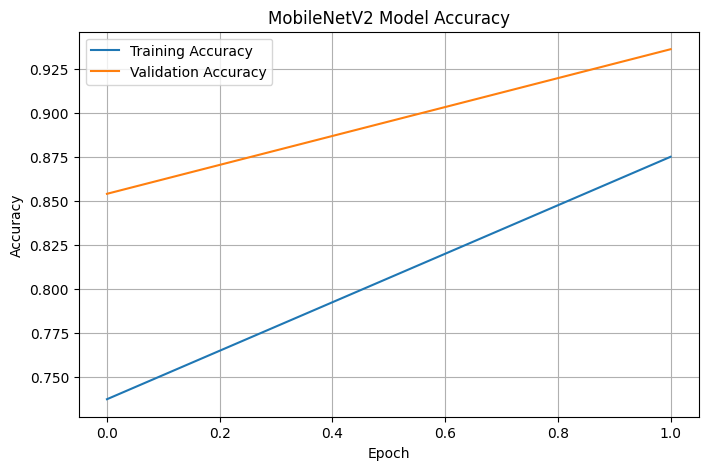

In [ ]:
plt.figure(figsize=(8, 5))

plt.plot(
    history.history["accuracy"],
    label="Training Accuracy"
)

plt.plot(
    history.history["val_accuracy"],
    label="Validation Accuracy"
)

plt.title("MobileNetV2 Model Accuracy")
plt.xlabel("Epoch")
plt.ylabel("Accuracy")
plt.legend()
plt.grid(True)
plt.show()

Saving cat.jpeg to cat.jpeg


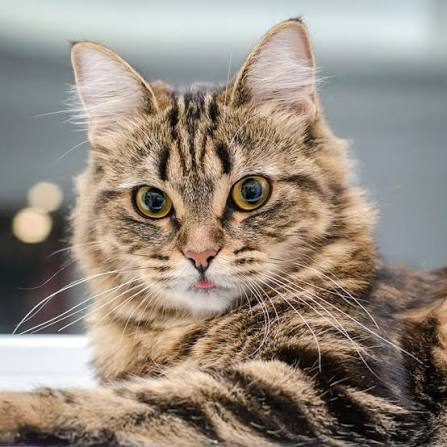

Prediction: Cat
Confidence: 87.29%


In [ ]:

from google.colab import files
from PIL import Image
from IPython.display import display
import numpy as np
import tensorflow as tf

# Upload an image from your computer
uploaded = files.upload()

for filename in uploaded.keys():
    image = Image.open(filename).convert("RGB")
    display(image)

    # Resize the image
    image = image.resize((224, 224))
    image_array = np.array(image, dtype=np.float32)
    image_array = np.expand_dims(image_array, axis=0)

    # Predict using the trained model
    prediction = model.predict(image_array, verbose=0)[0][0]

    if prediction >= 0.5:
        print("Prediction: Dog")
        print(f"Confidence: {prediction * 100:.2f}%")
    else:
        print("Prediction: Cat")
        print(f"Confidence: {(1 - prediction) * 100:.2f}%")


Upload a cat or dog image:


Saving cat.jpeg to cat (1).jpeg


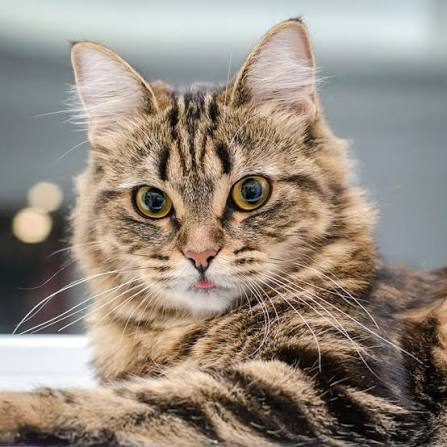

Prediction: Cat
Confidence: 87.29%
------------------------------
Do you want to predict another image? (yes/no): no


In [19]:

from google.colab import files
from PIL import Image
from IPython.display import display
import numpy as np

while True:
    print("Upload a cat or dog image:")
    uploaded = files.upload()

    if not uploaded:
        print("No image uploaded.")
        break

    for filename in uploaded:
        image = Image.open(filename).convert("RGB")
        display(image)

        image = image.resize((224, 224))
        image_array = np.array(image, dtype=np.float32)
        image_array = np.expand_dims(image_array, axis=0)

        prediction = model.predict(image_array, verbose=0)[0][0]

        if prediction >= 0.5:
            print("Prediction: Dog")
            print(f"Confidence: {prediction * 100:.2f}%")
        else:
            print("Prediction: Cat")
            print(f"Confidence: {(1 - prediction) * 100:.2f}%")

        print("-" * 30)

    again = input("Do you want to predict another image? (yes/no): ")

    if again.lower() != "yes":
        break


In [20]:
print("Model exists:", "model" in globals())
print("Validation data exists:", "validation_data" in globals())

Model exists: True
Validation data exists: True


In [21]:
loss, accuracy = model.evaluate(validation_data, verbose=1)

print("Validation Accuracy:", round(accuracy * 100, 2), "%")
print("Validation Loss:", round(loss, 4))

16/16 ━━━━━━━━━━━━━━━━━━━━ 29s 1s/step - accuracy: 0.9360 - loss: 0.3065
Validation Accuracy: 93.6 %
Validation Loss: 0.3065


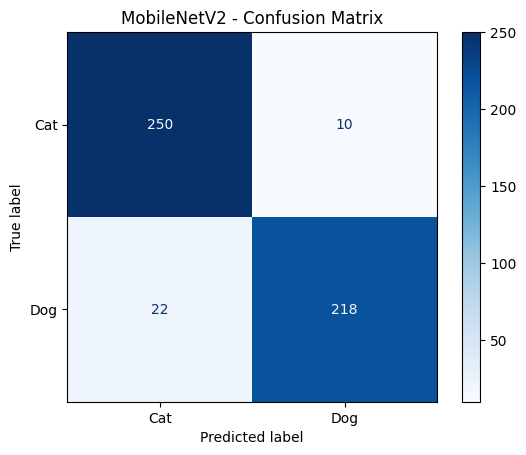

In [23]:

import numpy as np
import matplotlib.pyplot as plt
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay

# Collect actual labels and model predictions
actual_labels = []
predicted_labels = []

for images, labels in validation_data:
    predictions = model.predict(images, verbose=0).ravel()

    actual_labels.extend(labels.numpy().astype(int))
    predicted_labels.extend((predictions >= 0.5).astype(int))

# Create and display the confusion matrix
cm = confusion_matrix(
    actual_labels,
    predicted_labels,
    labels=[0, 1]
)

display = ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=["Cat", "Dog"]
)

display.plot(cmap="Blues", values_format="d")
plt.title("MobileNetV2 - Confusion Matrix")
plt.show()


In [24]:

from sklearn.metrics import classification_report

print("Classification Report")
print("----------------------")

print(classification_report(
    actual_labels,
    predicted_labels,
    labels=[0, 1],
    target_names=["Cat", "Dog"],
    digits=4
))


Classification Report
----------------------
              precision    recall  f1-score   support

         Cat     0.9191    0.9615    0.9398       260
         Dog     0.9561    0.9083    0.9316       240

    accuracy                         0.9360       500
   macro avg     0.9376    0.9349    0.9357       500
weighted avg     0.9369    0.9360    0.9359       500

